# Demo III: an autoencoder learns the space of signals

*Part III of the lecture "AI for Science: putting physics into learning". This notebook
can be read and run on its own: it needs only `numpy`, `matplotlib` and `torch`, and
takes well under a minute on a laptop CPU.*

## The question

Demos I and II learned a **function**: one input, one answer. A **generative model**
learns a **distribution** $p(x)$ instead: from many examples, it learns what the
plausible objects are (signals here; molecules, materials or images elsewhere), and it
can then be used in three ways:

1. **explore and generate**: produce new plausible objects;
2. **condition**: among all plausible objects, which ones agree with a measurement?
   The spread of the answers is an **uncertainty**;
3. **score**: is this new object plausible at all? If not, it is an **anomaly**, or
   **out of distribution**.

This demo does the three with the simplest generative model, a **variational
autoencoder** (VAE).

## The experiment, and where the physics is

The signal is the one of Demo I: something is kicked and left to ring. We have **2000
measured signals**, 64 samples each, with a little noise. Three levels of knowledge:

| | what it is | what the model gets |
|---|---|---|
| **the law** | every signal obeys $\ddot x + 2\gamma\,\dot x + \omega_0^2\, x = 0$ | nothing: we keep it to **check** what the model generates |
| **the parameters** | each signal has its own frequency $\omega$ and damping $\gamma$ | nothing: the model must find them (**latent variables**) |
| **their distribution** | which $(\omega, \gamma)$ occur: here $\omega \in [2, 4]$, $\gamma \in [0.1, 0.4]$ | nothing: learned **from the data** |

The model is a standard VAE, trained on the signals alone. All the physics it ends up
with comes from the data.

## What to look for

1. The autoencoder compresses 64 numbers into 2, and these 2 numbers turn out to be a
   map of frequency and damping.
2. Generation is a map from a known distribution to the data distribution: draw
   $z \sim \mathcal N(0, 1)$, decode. The generated signals obey the law better than the
   noisy data; their frequencies and dampings only roughly follow the training ranges.
3. Conditioning on a few noisy points gives a family of possible continuations: an
   uncertainty that shrinks as data are added, and that can be tested.
4. The same model flags signals unlike its training set. It finds the edge of the
   training data in frequency, and misses it in damping.

In [1]:
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import torch

torch.manual_seed(0)
np.random.seed(0)
torch.set_num_threads(4)
t_start = time.time()

BLUE, RED, GREEN, ORANGE, GREY = "#5073B8", "#B85050", "#50B873", "#EBA05A", "#888888"
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
os.makedirs("figures", exist_ok=True)      # each figure is also saved there as a PDF

## The signals

`signals` draws $\omega$ and $\gamma$ uniformly in their ranges and returns the
waveforms $x(t) = e^{-\gamma t}\cos(\omega t)$ with measurement noise (standard deviation
0.02). `x_train` is the whole training set: 2000 signals. The figure shows five of them,
with the frequency and damping used to make them (the model never sees these numbers).

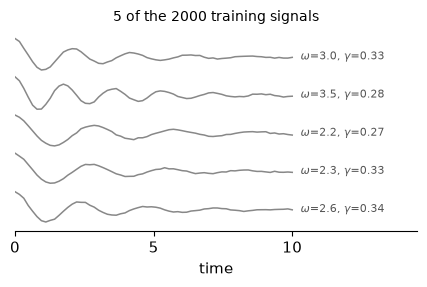

In [2]:
L = 64                                       # samples per waveform
tgrid = torch.linspace(0, 10, L)
OMEGA, GAMMA = (2.0, 4.0), (0.1, 0.4)
NOISE = 0.02
N_TRAIN = 2000


def uniform(n, lo, hi):
    return lo + (hi - lo) * torch.rand(n)


def clean(omega, gamma):
    return torch.exp(-gamma[:, None] * tgrid) * torch.cos(omega[:, None] * tgrid)


def waveform(omega, gamma, noise=NOISE):
    x = clean(omega, gamma)
    return x + noise * torch.randn(x.shape)


def signals(n):
    omega, gamma = uniform(n, *OMEGA), uniform(n, *GAMMA)
    return waveform(omega, gamma), omega, gamma


x_train, om_train, ga_train = signals(N_TRAIN)

fig, ax = plt.subplots(figsize=(4.4, 3.0))
for k in range(5):
    ax.plot(tgrid, x_train[k] - 2.1 * k, color=GREY, lw=1.1)
    ax.text(10.3, -2.1 * k, rf"$\omega$={om_train[k]:.1f}, $\gamma$={ga_train[k]:.2f}", va="center", fontsize=8, color="#555555")
ax.set_xlim(0, 14.5)
ax.set_xticks([0, 5, 10])
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.set_xlabel("time")
ax.set_title("5 of the 2000 training signals", fontsize=10)
fig.tight_layout()
fig.savefig("figures/fig_III_vae_data.pdf")
plt.show()

## The law as a test

A solution of $\ddot x + 2\gamma\dot x + \omega_0^2 x = 0$ sampled at regular intervals
$\Delta$ obeys an exact three-point relation,

$$x_{n+1} = a\, x_n + b\, x_{n-1}, \qquad a = 2 e^{-\gamma\Delta}\cos\omega\Delta, \quad b = -e^{-2\gamma\Delta}$$

with the same two constants $a, b$ along the whole signal. This is the equation of
motion written for sampled data. `law_residual` takes a batch of waveforms, finds for
each one the best constants $(a, b)$ by least squares, and returns what is left:

$$r_n = x_{n+1} - a\, x_n - b\, x_{n-1}$$

For a damped oscillation, **whatever its frequency and damping**, $r = 0$. The function
does not need to know $\omega$ and $\gamma$: it only asks whether *some* damped
oscillator could have produced the waveform. The model never sees it; we use it later
to test the generated signals.

In [3]:
def law_residual(x):
    """Residual of the best three-point law x[n+1] = a x[n] + b x[n-1], for each waveform."""
    x0, x1, y = x[:, 1:-1], x[:, :-2], x[:, 2:]
    s00, s11, s01 = (x0 * x0).sum(1) + 1e-4, (x1 * x1).sum(1) + 1e-4, (x0 * x1).sum(1)
    t0, t1 = (x0 * y).sum(1), (x1 * y).sum(1)
    det = s00 * s11 - s01**2
    a, b = (s11 * t0 - s01 * t1) / det, (s00 * t1 - s01 * t0) / det      # least squares, 2 unknowns
    return y - a[:, None] * x0 - b[:, None] * x1


def violation(x):
    """RMS of the law residual: one number per waveform, 0 for a damped oscillation."""
    return law_residual(x).pow(2).mean(1).sqrt()

## A variational autoencoder

Two networks, trained together:

- the **encoder** compresses a waveform $x$ (64 numbers) into a point $z$ of a small
  **latent space** (here 2 numbers), or more precisely into a small Gaussian cloud
  around a point, $q(z \mid x) = \mathcal N(\mu(x), \sigma(x)^2)$;
- the **decoder** rebuilds a waveform $D(z)$ from $z$.

The loss has two terms:

$$\mathcal L = \underbrace{\frac{\| x - D(z) \|^2}{2\sigma_d^2}}_{\text{reconstruct the data}}
\;+\; \underbrace{\mathrm{KL}\big(q(z\mid x)\,\|\,\mathcal N(0, 1)\big)}_{\text{latent points} \,\sim\, \mathcal N(0,1)}$$

The second one asks that the latent points of the data look like a standard Gaussian.
This is what makes the autoencoder a generative model: the decoder becomes a **map
from a known distribution to the data distribution**. To generate, draw
$z \sim \mathcal N(0, 1)$ and decode. $\sigma_d$ sets the balance between the two terms.

Minus the loss is a lower bound on $\ln p(x)$ (the "ELBO"); we use it in the last
section.

The cell trains the model; this is the slow cell.

In [4]:
LATENT, SIGMA_D = 2, 0.1


def mlp(n_in, n_out, width=256):
    return torch.nn.Sequential(
        torch.nn.Linear(n_in, width), torch.nn.SiLU(),
        torch.nn.Linear(width, width), torch.nn.SiLU(),
        torch.nn.Linear(width, n_out))


class VAE(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder, self.decoder = mlp(L, 2 * LATENT), mlp(LATENT, L)

    def encode(self, x):
        mu, logvar = self.encoder(x).chunk(2, dim=1)
        return mu, torch.exp(0.5 * logvar)

    def loss_terms(self, x):
        """Reconstruction and KL terms of the VAE loss, for each waveform."""
        mu, sigma = self.encode(x)
        z = mu + sigma * torch.randn_like(mu)                         # a point of the cloud
        rec = ((self.decoder(z) - x) ** 2).sum(1) / (2 * SIGMA_D**2)
        kl = 0.5 * (mu**2 + sigma**2 - 1 - 2 * torch.log(sigma)).sum(1)
        return rec, kl


def train(steps=12000, batch=128):
    model = VAE()
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    for _ in range(steps):
        rec, kl = model.loss_terms(x_train[torch.randint(N_TRAIN, (batch,))])
        loss = (rec + kl).mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
    return model


model = train()
torch.set_grad_enabled(False)                # training is over

x_test, om_test, ga_test = signals(2000)
truth_test = clean(om_test, ga_test)
err = ((model.decoder(model.encode(x_test)[0]) - truth_test) ** 2).mean().sqrt()
print(f"reconstruction error on new signals = {err:.3f}   (noise level {NOISE})")
print(f"trained in {time.time() - t_start:.0f} s")

reconstruction error on new signals = 0.006   (noise level 0.02)
trained in 30 s


Reconstruction error is measured on 2000 **new** signals, against the noise-free truth.
It is below the noise level: two numbers are enough to describe a signal, and going
through them removes most of the noise.

## The latent space is a map of the signals

Left and middle: 2000 new signals placed at their latent coordinates $(z_1, z_2)$,
coloured by their true frequency, then by their true damping. Nobody told the network
that the signals had two parameters, or which ones: it had to find a 2D description,
and it found a (distorted) map of $(\omega, \gamma)$.

Right: the reverse walk. Pick points on a regular grid of the latent space and decode
them. Moving in the latent space changes the signal smoothly.

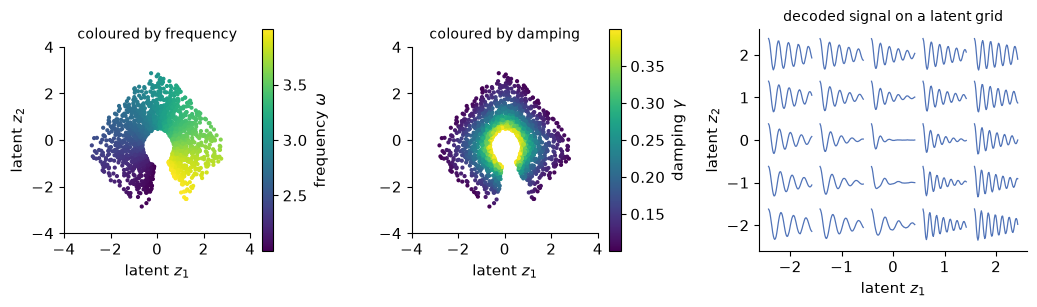

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.2), gridspec_kw={"width_ratios": [1, 1, 1.15]})
z_test = model.encode(x_test)[0]
for ax, val, name in zip(axes[:2], [om_test, ga_test], [r"frequency $\omega$", r"damping $\gamma$"]):
    sc = ax.scatter(z_test[:, 0], z_test[:, 1], c=val, s=4, cmap="viridis")
    fig.colorbar(sc, ax=ax, label=name)
    ax.set_xlabel("latent $z_1$")
    ax.set_xlim(-4, 4)
    ax.set_ylim(-4, 4)
    ax.set_aspect("equal")
    ax.set_title(f"coloured by {name.split()[0]}", fontsize=10)
axes[0].set_ylabel("latent $z_2$")

ax = axes[2]
nodes = np.linspace(-2, 2, 5)
for i, z1 in enumerate(nodes):
    for j, z2 in enumerate(nodes):
        w = model.decoder(torch.tensor([[z1, z2]], dtype=torch.float32))[0]
        ax.plot(z1 - 0.42 + 0.84 * tgrid / 10, z2 + 0.38 * w, color=BLUE, lw=0.9)
ax.set_xticks(nodes)
ax.set_yticks(nodes)
ax.set_xlabel("latent $z_1$")
ax.set_ylabel("latent $z_2$")
ax.set_xlim(-2.6, 2.6)
ax.set_ylim(-2.6, 2.6)
ax.set_title("decoded signal on a latent grid", fontsize=10)
fig.tight_layout()
fig.savefig("figures/fig_III_vae_latent.pdf")
plt.show()

## Generate, then check the physics

Generation: draw $z \sim \mathcal N(0, 1)$, decode. The model was given no physics, so
what it generates has to be tested. Two separate questions can be put in numbers.

**1. Does each generated signal obey the law?** `violation` answers.

**2. Is the distribution right?** `fit_oscillation` finds, for each waveform, the best
$(\omega, \gamma)$ on a fine grid, much larger than the training ranges. The fitted
values of the generated signals should fill the training rectangle and not leak out.

law violation: generated signals 0.0051   noisy training signals 0.0425


inside the training ranges: generated signals 77%   new real signals 100%


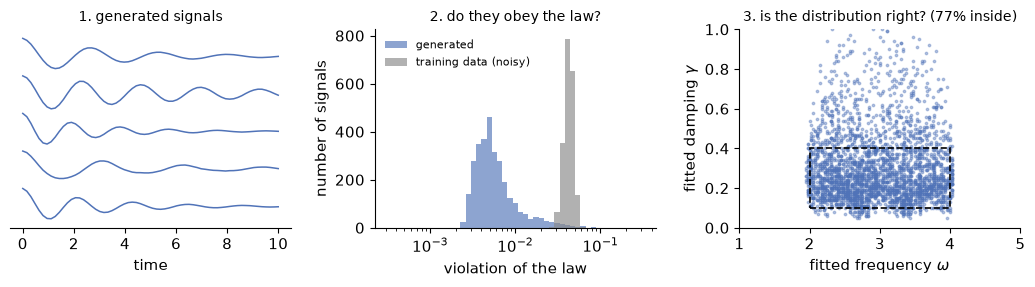

In [6]:
om_grid, ga_grid = torch.linspace(0.5, 7, 261), torch.linspace(0.0, 1.5, 151)
OM, GA = (g.reshape(-1) for g in torch.meshgrid(om_grid, ga_grid, indexing="ij"))
templates = clean(OM, GA)
templates = templates / templates.norm(dim=1, keepdim=True)


def fit_oscillation(x):
    """Best (omega, gamma) on the grid for each waveform."""
    best = ((x @ templates.T) ** 2).argmax(1)
    return OM[best], GA[best]


def inside(x):
    om, ga = fit_oscillation(x)
    ok = (om > OMEGA[0] - 0.05) & (om < OMEGA[1] + 0.05) & (ga > GAMMA[0] - 0.02) & (ga < GAMMA[1] + 0.02)
    return 100 * ok.float().mean().item()


x_gen = model.decoder(torch.randn(3000, LATENT))
print(f"law violation: generated signals {violation(x_gen).median():.4f}   "
      f"noisy training signals {violation(x_train).median():.4f}")
print(f"inside the training ranges: generated signals {inside(x_gen):.0f}%   new real signals {inside(x_test):.0f}%")

fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.0))
ax = axes[0]
for k in range(5):
    ax.plot(tgrid, x_gen[k] - 2.1 * k, color=BLUE, lw=1.1)
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.set_xlabel("time")
ax.set_title("1. generated signals", fontsize=10)

ax = axes[1]
bins = np.logspace(-3.5, -0.5, 50)
ax.hist(violation(x_gen).numpy(), bins=bins, color=BLUE, alpha=0.65, label="generated")
ax.hist(violation(x_train).numpy(), bins=bins, color=GREY, alpha=0.65, label="training data (noisy)")
ax.set_xscale("log")
ax.set_xlabel("violation of the law")
ax.set_ylabel("number of signals")
ax.set_title("2. do they obey the law?", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="upper left")

ax = axes[2]
om, ga = fit_oscillation(x_gen)
ax.scatter(om, ga, s=3, alpha=0.4, color=BLUE)
ax.add_patch(plt.Rectangle((OMEGA[0], GAMMA[0]), OMEGA[1] - OMEGA[0], GAMMA[1] - GAMMA[0],
                           fill=False, edgecolor="k", lw=1.2, ls="--"))
ax.set_xlim(1, 5)
ax.set_ylim(0, 1.0)
ax.set_xlabel(r"fitted frequency $\omega$")
ax.set_ylabel(r"fitted damping $\gamma$")
ax.set_title(f"3. is the distribution right? ({inside(x_gen):.0f}% inside)", fontsize=10)
fig.tight_layout()
fig.savefig("figures/fig_III_vae_check.pdf")
plt.show()

**The law.** Nobody gave it to the model, and the generated signals obey it more closely
than the noisy data they were learned from: the decoder has learned the common form of
the signals and left the noise out.

**The distribution.** Most generated signals have a frequency and a damping inside the
dashed rectangle, the range of the training signals, but a good fraction leak out,
mostly towards high damping. The training loss only asks the latent points of the data
to look *roughly* Gaussian. Look at the latent maps above: there is a hole at the
centre, and the edges are not those of a Gaussian. Draws of $\mathcal N(0, 1)$ that land
where no training signal was encoded are decoded all the same: the decoder extrapolates
there. These signals are physical, and not what the data contain.

Both checks use knowledge that the model does not have. This is the usual situation
with a generative model in science: generate, then test against what we know.

## Conditioning: from generation to uncertainty

Now a measurement: the first few points of a signal, with a poor sensor (noise 0.1, five
times the training noise). What is the rest of the signal?

There is no single answer: several signals agree with the same points. The generative
model gives **all of them**. It knows what signals look like, $p(z)$, and for each $z$
we can compute how well $D(z)$ agrees with the measurement $y$. Bayes' rule combines
the two:

$$p(z \mid y) \;\propto\; p(z)\; \exp\!\Big(-\frac{\| y - D(z)_{\text{observed}} \|^2}{2\sigma_y^2}\Big)$$

The generative model is the **prior**: it restricts the search to physical signals of
the kind seen in training, with $p(z) = \mathcal N(0, 1)$. The latent space has two
dimensions, so `posterior_samples` simply evaluates this on a grid and draws from it.
(In higher dimension one trains a conditional model, or samples with Monte Carlo; the
idea is the same.) Decoding the draws gives a bundle of possible continuations, and
their spread is the uncertainty.

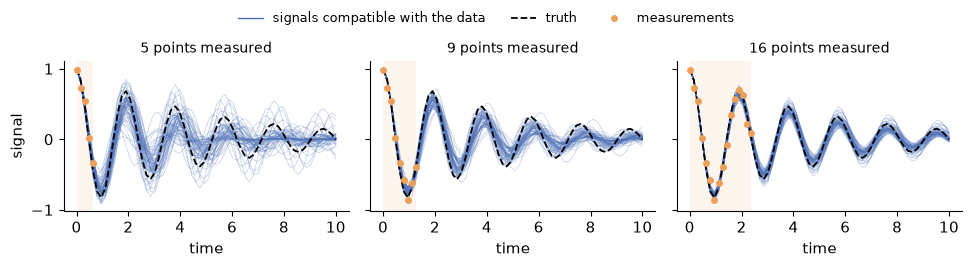

In [7]:
z_axis = torch.linspace(-5, 5, 201)
Z = torch.stack([g.reshape(-1) for g in torch.meshgrid(z_axis, z_axis, indexing="ij")], 1)
DZ = model.decoder(Z)                        # every signal the model can produce
LOG_PRIOR = -(Z**2).sum(1) / 2             # the prior N(0, 1)
SIGMA_Y = 0.1


def posterior_samples(y, n_draws=200):
    """Signals compatible with the measurements y (the first y.shape[1] points)."""
    m = y.shape[1]
    logp = LOG_PRIOR - ((y[:, None, :] - DZ[None, :, :m]) ** 2).sum(-1) / (2 * SIGMA_Y**2)
    idx = torch.multinomial(torch.softmax(logp, 1), n_draws, replacement=True)
    return DZ[idx]                           # (number of measurements, n_draws, L)


om_t, ga_t = torch.tensor([3.3]), torch.tensor([0.2])
truth = clean(om_t, ga_t)
noise_y = SIGMA_Y * torch.randn(1, L)
fig, axes = plt.subplots(1, 3, figsize=(10, 2.7), sharey=True)
for ax, m in zip(axes, [5, 9, 16]):
    y = (truth + noise_y)[:, :m]
    draws = posterior_samples(y)[0]
    ax.plot(tgrid, draws[:60].T, color=BLUE, lw=0.6, alpha=0.3)
    ax.plot(tgrid, truth[0], color="k", lw=1.3, ls="--")
    ax.plot(tgrid[:m], y[0], "o", color=ORANGE, ms=4, zorder=5)
    ax.axvspan(0, tgrid[m - 1], color=ORANGE, alpha=0.1, lw=0)
    ax.set_title(f"{m} points measured", fontsize=10)
    ax.set_xlabel("time")
axes[0].set_ylabel("signal")
handles = [plt.Line2D([], [], color=BLUE, lw=1, label="signals compatible with the data"),
           plt.Line2D([], [], color="k", lw=1.3, ls="--", label="truth"),
           plt.Line2D([], [], marker="o", ls="", color=ORANGE, ms=4, label="measurements")]
fig.legend(handles=handles, frameon=False, fontsize=9, ncol=3, loc="upper center")
fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig("figures/fig_III_vae_conditioning.pdf")
plt.show()

With 5 points the frequency is barely constrained and the continuations fan out. With
16 points they collapse onto the truth. Note that the bundle is not a blurred band
around one curve: each blue line is a possible signal.

**Is this uncertainty honest?** It can be tested. Repeat the experiment on 500 new
signals, build for each the band that contains 90% of the draws, and count how often
the true signal is inside. A calibrated model gives 90%.

In [8]:
n = 500
x_t, om_t, ga_t = signals(n)
for m in [5, 9, 16]:
    y = clean(om_t, ga_t)[:, :m] + SIGMA_Y * torch.randn(n, m)
    draws = posterior_samples(y)
    lo, hi = draws.quantile(0.05, dim=1), draws.quantile(0.95, dim=1)
    target = clean(om_t, ga_t)
    covered = ((target >= lo) & (target <= hi))[:, m:].float().mean()
    print(f"{m:2d} points measured: the 90% band contains the truth {100 * covered:.0f}% of the time, "
          f"mean width {(hi - lo)[:, m:].mean():.2f}")

 5 points measured: the 90% band contains the truth 89% of the time, mean width 0.48


 9 points measured: the 90% band contains the truth 90% of the time, mean width 0.32


16 points measured: the 90% band contains the truth 88% of the time, mean width 0.17


Close to 90%, and the band narrows as measurements are added. This works because the
test signals come from the same family as the training signals. The next section is
about what happens when they do not.

## Anomaly detection: low-probability signals

The loss $\mathcal L(x)$ of the VAE is (minus a lower bound on) the log-probability of
$x$ under the model. Evaluated on a new signal it is an **anomaly score**: low when the
signal resembles the training set, high when the model can neither reconstruct it nor
place it in the latent space,

$$s(x) = \mathcal L(x) \;\gtrsim\; -\ln p(x)$$

The threshold is set on normal signals only: the score exceeded by 1% of them. No
example of a fault is needed. We try:

- **frequency and damping sweeps**: clean damped oscillations, moved across and beyond
  the training ranges;
- **a glitch**: a normal signal with one sample displaced by 0.3;
- **an instability**: an oscillation that grows instead of decaying;
- **an overdamped signal**: damping 0.5 to 0.6, above the training range.

normal      : median score =     7.7   flagged: 1%
glitch      : median score =    12.1   flagged: 93%
instability : median score =   186.9   flagged: 100%
overdamped  : median score =     7.6   flagged: 7%


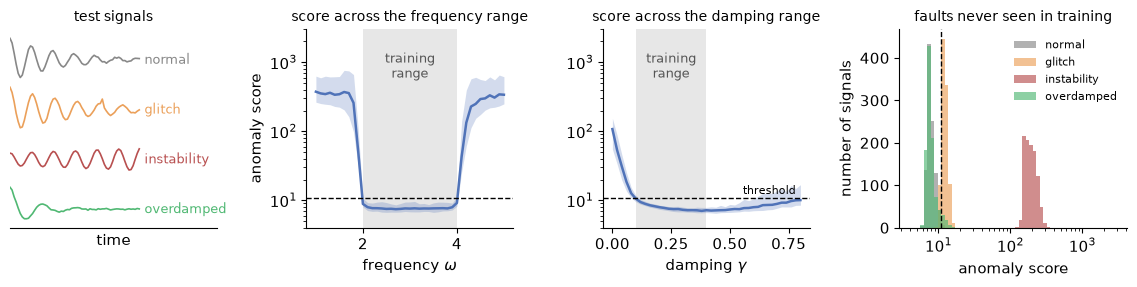

total runtime: 36 s


In [9]:
def score(x, draws=8):
    return sum(sum(model.loss_terms(x)) for _ in range(draws)) / draws


n = 1000
x_normal = signals(n)[0]
x_glitch = signals(n)[0]
x_glitch[torch.arange(n), torch.randint(5, L - 5, (n,))] += 0.3 * torch.sign(torch.randn(n))
x_growing = 0.3 * waveform(uniform(n, *OMEGA), -uniform(n, 0.02, 0.1))
x_over = waveform(uniform(n, *OMEGA), uniform(n, 0.5, 0.6))
tests = {"normal": (x_normal, GREY), "glitch": (x_glitch, ORANGE),
         "instability": (x_growing, RED), "overdamped": (x_over, GREEN)}

scores = {k: score(x) for k, (x, _) in tests.items()}
threshold = scores["normal"].quantile(0.99)
for k, s in scores.items():
    print(f"{k:12s}: median score = {s.median():7.1f}   flagged: {100 * (s > threshold).float().mean():.0f}%")


def sweep(values, make):
    s = torch.stack([score(make(torch.full((200,), v.item()))) for v in values])
    return (s.quantile(q, dim=1) for q in (0.1, 0.5, 0.9))


om_sweep, ga_sweep = torch.linspace(1, 5, 41), torch.linspace(0.0, 0.8, 41)
sweeps = [(om_sweep, sweep(om_sweep, lambda w: waveform(w, uniform(200, *GAMMA))), OMEGA, r"frequency $\omega$"),
          (ga_sweep, sweep(ga_sweep, lambda g: waveform(uniform(200, *OMEGA), g)), GAMMA, r"damping $\gamma$")]

fig, axes = plt.subplots(1, 4, figsize=(11.5, 3.0), gridspec_kw={"width_ratios": [1, 1, 1, 1.1]})
ax = axes[0]
for k, (name, (x, c)) in enumerate(tests.items()):
    ax.plot(tgrid, x[0] - 2.3 * k, color=c, lw=1.2)
    ax.text(10.4, -2.3 * k, name, color=c, va="center", fontsize=9)
ax.set_xlim(0, 16)
ax.set_xticks([])
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.set_xlabel("time")
ax.set_title("test signals", fontsize=10)

for ax, (values, (q10, q50, q90), rng, name) in zip(axes[1:3], sweeps):
    ax.axvspan(*rng, color=GREY, alpha=0.2, lw=0)
    ax.fill_between(values, q10, q90, color=BLUE, alpha=0.25, lw=0)
    ax.plot(values, q50, color=BLUE, lw=1.8)
    ax.axhline(threshold, color="k", ls="--", lw=1)
    ax.set_yscale("log")
    ax.set_ylim(4, 3000)
    ax.set_xlabel(name)
    ax.set_title(f"score across the {name.split()[0]} range", fontsize=10)
    ax.text(sum(rng) / 2, 600, "training\nrange", ha="center", fontsize=9, color="#555555")
axes[1].set_ylabel("anomaly score")
axes[2].text(0.78, threshold * 1.15, "threshold", fontsize=8, ha="right")

ax = axes[3]
bins = np.logspace(np.log10(4), np.log10(3000), 60)
for name, (_, c) in tests.items():
    ax.hist(scores[name].numpy(), bins=bins, color=c, alpha=0.65, label=name)
ax.axvline(threshold, color="k", ls="--", lw=1)
ax.set_xscale("log")
ax.set_xlabel("anomaly score")
ax.set_ylabel("number of signals")
ax.set_title("faults never seen in training", fontsize=10)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig("figures/fig_III_vae_anomaly.pdf")
plt.show()

print(f"total runtime: {time.time() - t_start:.0f} s")

**Frequency.** Inside the training range the score is flat and low; it takes off within
a tenth of the edges, on both sides. The model has located the boundary of what it
knows, although nobody gave it the numbers 2 and 4. A signal at $\omega = 4.5$ is a
perfectly good damped oscillation: it is flagged because it is **new**, not because it
is wrong. That is what "out of distribution" means.

**Faults.** The glitch and the instability are flagged, with a threshold tuned on normal
data only.

**The pitfall: damping.** On the low side the edge is found. On the high side the score
hardly moves: overdamped signals, outside the training range, pass as normal. A signal
that dies faster is a short normal-looking start followed by something close to zero,
which the decoder reproduces without effort. The score measures how well the *numbers*
are explained, not whether the *situation* was seen before. A low score is not a
certificate; this weakness of likelihood-based detection is well documented
(Nalisnick et al. 2019). Keep physical checks next to the learned one: here, the fitted
damping of the previous section would catch it at once.

## Take-home messages

- A generative model learns the **space of plausible objects** from examples. An
  autoencoder makes this space explicit: a few latent coordinates, here a map of the
  physical parameters, found without being told.
- **Generation is a map** from a known distribution, $\mathcal N(0, 1)$, to the data
  distribution. The match is never exact.
- **Check with numbers**: violation of the law, distributions of fitted parameters.
  Curves that look right can fail both.
- **Conditioning turns generation into uncertainty**: the set of signals compatible with
  a measurement. Its calibration can and should be tested.
- **Low probability under the model = anomaly**, with no example of a fault. But out of
  distribution is not the same as faulty, and a low score is not a certificate.

## Things to try

1. Give the latent space 1 dimension, then 4 (`LATENT`; the latent-map and conditioning
   cells assume 2). What happens to the reconstruction error?
2. Change the balance `SIGMA_D` (0.02, 0.2). Watch the reconstruction error, the shape of
   the latent cloud and the fraction of generated signals inside the training ranges.
3. Make the glitch smaller (0.15, then 0.05). When does it disappear below the
   threshold? Compare with the noise level.
4. Catch the overdamped signals: add the fitted damping from `fit_oscillation` as a
   second, physical test.
5. Condition on points in the middle of the signal instead of the beginning.
6. Train on 100 signals instead of 2000 (`N_TRAIN`). Which of the results above survive?
7. Add the law to the loss, as a soft constraint (Part I): `law_residual` applied to
   signals decoded from random latent points.